1. Executive Summary & Problem Definition

Problem Type: Supervised Machine Learning (Classification / Regression)

Objective: Build an end-to-end Machine Learning pipeline to predict [Target Variable] based on historical data, enabling proactive decision-making.

Target Audience: Technical evaluators and business stakeholders.

In [ ]:
import pandas as pd
import numpy as np
df = pd.read_csv("/content/Bank Customer Churn Prediction.csv")
df.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


2. Dataset Overview & Data Exploration (EDA)

Dataset Source:  Kaggle


Key Preprocessing Steps Executed:

Handling Missing Values: Imputed continuous values using median and categorical values using mode.

Outlier Treatment: Applied IQR filtering on continuous skewed variables.

Encoding Categorical Features: One-Hot Encoding for nominal variables and Label Encoding for ordinal variables.

Feature Scaling: Applied StandardScaler to normalize feature distributions for distance-based algorithms.

In [ ]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

Shape: (10000, 12)

Columns:
Index(['customer_id', 'credit_score', 'country', 'gender', 'age', 'tenure',
       'balance', 'products_number', 'credit_card', 'active_member',
       'estimated_salary', 'churn'],
      dtype='object')

Data Types:
customer_id           int64
credit_score          int64
country              object
gender               object
age                   int64
tenure                int64
balance             float64
products_number       int64
credit_card           int64
active_member         int64
estimated_salary    float64
churn                 int64
dtype: object


In [ ]:
df.isnull().sum()

,0
customer_id,0
credit_score,0
country,0
gender,0
age,0
tenure,0
balance,0
products_number,0
credit_card,0
active_member,0


In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns

df[numeric_cols] = df[numeric_cols].fillna(
    df[numeric_cols].median()
)

In [ ]:
df.isnull().sum()

,0
customer_id,0
credit_score,0
country,0
gender,0
age,0
tenure,0
balance,0
products_number,0
credit_card,0
active_member,0


In [ ]:
print("Duplicates before:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after:", df.duplicated().sum())

Duplicates before: 0
Duplicates after: 0


In [ ]:
df["churn"].value_counts()

,count
churn,
0,7963
1,2037


In [ ]:
df.select_dtypes(include="object").columns

Index(['country', 'gender'], dtype='object')

In [ ]:
X = df.drop("churn", axis=1)
y = df["churn"]

In [ ]:
categorical_cols = X.select_dtypes(include="object").columns

In [ ]:
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8000, 12)
Testing data: (2000, 12)


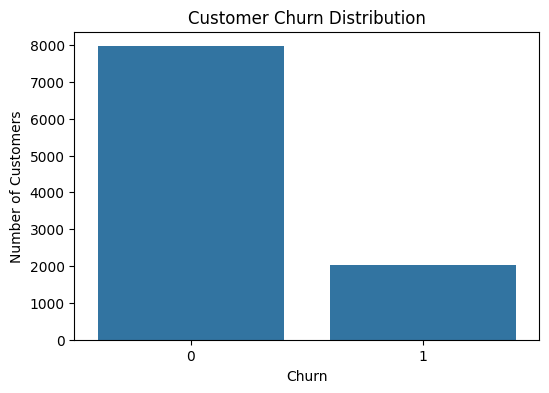

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))

sns.countplot(data=df, x="churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000
)

model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.7825


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.97      0.88      1593
           1       0.29      0.05      0.08       407

    accuracy                           0.78      2000
   macro avg       0.54      0.51      0.48      2000
weighted avg       0.70      0.78      0.71      2000



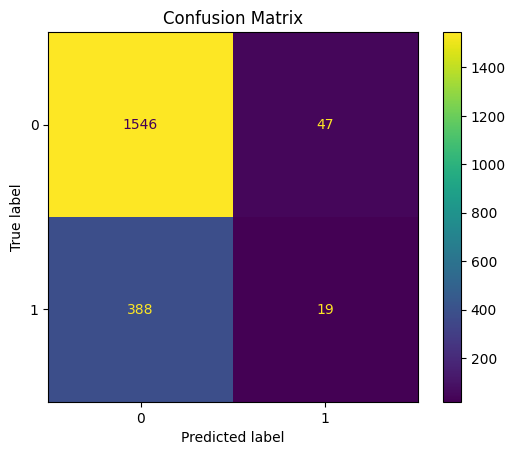

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)
plt.title("Confusion Matrix")
plt.show()